In [1]:
# Task 1: Load and inspect data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv'
births = pd.read_csv(url)

# First five rows
print(births.head())

# Shape of the DataFrame
print("Shape:", births.shape)

# Column dtypes
print(births.dtypes)

# dtype of the day column
print("Dtype of day column:", births['day'].dtype)
print("Missing values in day:", births['day'].isna().sum())

   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548
Shape: (15547, 5)
year        int64
month       int64
day       float64
gender        str
births      int64
dtype: object
Dtype of day column: float64
Missing values in day: 480


In [3]:
# Add decade column
births['decade'] = 10 * (births['year'] // 10)

# Pivot table of total births by decade and gender
decade_gender = births.pivot_table('births', index='decade', columns='gender', aggfunc='sum')
print(decade_gender)

gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428


In [4]:
# (a) Check male births are higher than female births in every decade
print(decade_gender['M'] > decade_gender['F'])
print("Male > Female in every decade:", (decade_gender['M'] > decade_gender['F']).all())

decade
1960    True
1970    True
1980    True
1990    True
2000    True
dtype: bool
Male > Female in every decade: True


In [5]:
# (b) Male-to-female ratio for each decade
ratio = decade_gender['M'] / decade_gender['F']
print(ratio)

# Percentage by which male births exceed female births
pct_excess = (ratio - 1) * 100
print(pct_excess)

decade
1960    1.052997
1970    1.052787
1980    1.050960
1990    1.048312
2000    1.048116
dtype: float64
decade
1960    5.299738
1970    5.278676
1980    5.096030
1990    4.831239
2000    4.811587
dtype: float64


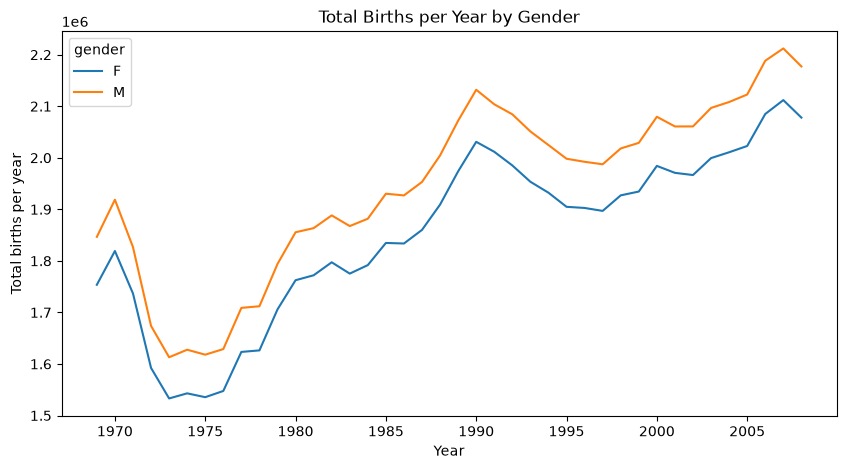

In [6]:
# (c) Total births per year by gender
yearly = births.pivot_table('births', index='year', columns='gender', aggfunc='sum')

# Plot with labelled axes and title
ax = yearly.plot(figsize=(10, 5))
ax.set_xlabel('Year')
ax.set_ylabel('Total births per year')
ax.set_title('Total Births per Year by Gender')
plt.show()

# Long-term gap: males exceed females by about 5%

In [7]:

# (a) Quartiles of the births column
quartiles = np.percentile(births['births'], [25, 50, 75])
print("Q1, Median, Q3:", quartiles)

# Median as robust mean
mu = quartiles[1]

# Robust standard deviation
sig = 0.74 * (quartiles[2] - quartiles[0])
print("mu =", mu)
print("sig =", sig)

# Why 0.74? For a normal distribution, IQR = 1.349 * sigma,
# so sigma = IQR / 1.349 = 0.74 * IQR (approximately)

# (b) Keep only rows within 5 sigma of mu
n_before = len(births)
births_clean = births.query('(births > @mu - 5 * @sig) & (births < @mu + 5 * @sig)').copy()

# Report how many rows were removed
print("Rows before:", n_before)
print("Rows after:", len(births_clean))
print("Rows removed:", n_before - len(births_clean))

# (c) Convert day column to integers
births_clean['day'] = births_clean['day'].astype(int)
print(births_clean['day'].dtype)

# Not possible before because day had NaN values,
# and integer dtype cannot store NaN. Clipping removed those rows.

Q1, Median, Q3: [4358.  4814.  5289.5]
mu = 4814.0
sig = 689.31
Rows before: 15547
Rows after: 14610
Rows removed: 937
int64


            year  month  day gender  births  decade  dayofweek
1969-01-01  1969      1    1      F    4046    1960          2
1969-01-01  1969      1    1      M    4440    1960          2
1969-01-02  1969      1    2      F    4454    1960          3
1969-01-02  1969      1    2      M    4548    1960          3
1969-01-03  1969      1    3      F    4548    1960          4
decade            1960         1970         1980
dayofweek                                       
0          5063.826923  4689.097701  5276.907249
1          5286.096154  4885.252399  5503.842553
2          5074.622642  4750.376200  5367.642553
3          4978.288462  4696.923372  5333.485106
4          5107.884615  4782.095785  5393.087234
5          4651.057692  4207.784483  4483.901064
6          4342.346154  3979.278736  4308.120469


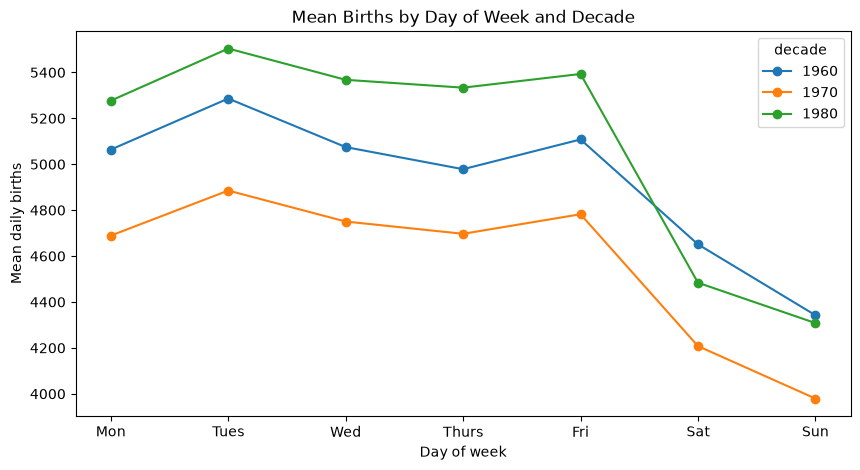

Years covered: 1969 - 1988
Decades present: [np.int64(1960), np.int64(1970), np.int64(1980)]


In [8]:

# (a) Combine year, month, day into a DatetimeIndex
births_clean.index = pd.to_datetime(10000 * births_clean['year'] +
                                    100 * births_clean['month'] +
                                    births_clean['day'], format='%Y%m%d')

# Add dayofweek column (0 = Monday, 6 = Sunday)
births_clean['dayofweek'] = births_clean.index.dayofweek
print(births_clean.head())

# (b) Pivot table of mean births: dayofweek as index, decade as columns
dow_decade = births_clean.pivot_table('births', index='dayofweek', columns='decade', aggfunc='mean')
print(dow_decade)

# Plot with tick labels Mon to Sun
ax = dow_decade.plot(figsize=(10, 5), marker='o')
ax.set_xticks(range(7))
ax.set_xticklabels(['Mon', 'Tues', 'Wed', 'Thurs', 'Fri', 'Sat', 'Sun'])
ax.set_xlabel('Day of week')
ax.set_ylabel('Mean daily births')
ax.set_title('Mean Births by Day of Week and Decade')
plt.show()

# (c) Check which years and decades are in the data
print("Years covered:", births_clean['year'].min(), "-", births_clean['year'].max())
print("Decades present:", sorted(births_clean['decade'].unique()))

# Weekends are lower because many births are scheduled (C-sections, inductions)
# on weekdays.
# 1990s and 2000s are missing because the data only covers 1969-1988.

       births
1 1  4009.225
  2  4247.400
  3  4500.900
  4  4571.350
  5  4603.625
              births
2012-01-01  4009.225
2012-01-02  4247.400
2012-01-03  4500.900
2012-01-04  4571.350
2012-01-05  4603.625


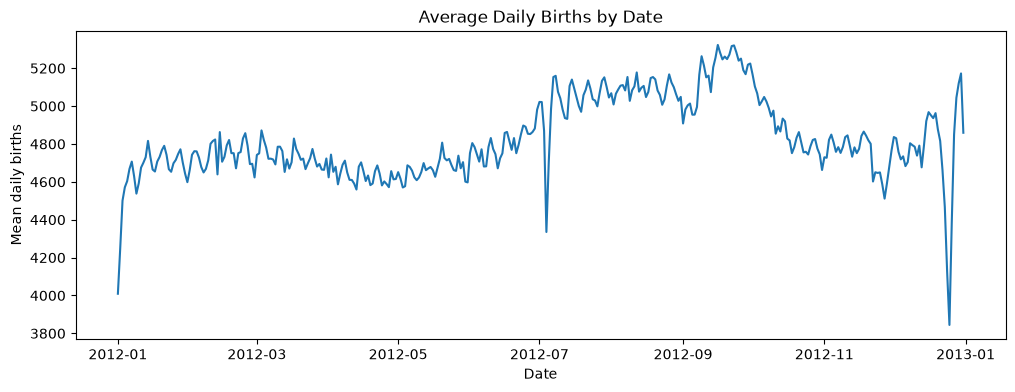

2012-12-25    3844.450
2012-01-01    4009.225
2012-12-24    4126.250
2012-01-02    4247.400
2012-07-04    4335.325
2012-12-26    4383.525
2012-12-23    4466.675
2012-01-03    4500.900
2012-11-27    4511.550
2012-01-09    4537.775
Name: births, dtype: float64


In [9]:

# (a) Mean births for each calendar date using a (month, day) multi-index
births_by_date = births_clean.pivot_table('births',
                                          [births_clean.index.month, births_clean.index.day])
print(births_by_date.head())

# Convert (month, day) into dates by attaching a dummy year
# 2012 is a leap year, so Feb 29 is also a valid date
births_by_date.index = [pd.Timestamp(2012, month, day) for (month, day) in births_by_date.index]
print(births_by_date.head())

# (b) Plot mean births by date (figure size 12 x 4)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(births_by_date.index, births_by_date['births'])
ax.set_xlabel('Date')
ax.set_ylabel('Mean daily births')
ax.set_title('Average Daily Births by Date')
plt.show()

# (c) Find the dates with the lowest mean births (the dips)
print(births_by_date['births'].nsmallest(10))

# Dips match US holidays: New Year's Day (Jan 1), Independence Day (Jul 4),
# Labor Day (early Sep), Thanksgiving (late Nov), Christmas (Dec 25).
# They most likely reflect scheduled or induced births (C-sections, inductions)
# avoided on holidays, not natural births.

In [11]:

# (a) Reproduce the decade-by-gender table using groupby
gb_table = births.groupby(['decade', 'gender'])['births'].sum().unstack()
print(gb_table)

# Confirm it matches the pivot table from Task 2
print("Matches pivot table:", np.allclose(gb_table, decade_gender))

# (b) Time both methods
t_pivot = %timeit -o births.pivot_table('births', index='decade', columns='gender', aggfunc='sum')
t_group = %timeit -o births.groupby(['decade', 'gender'])['births'].sum().unstack()

# Tabulate the timing results
timing = pd.DataFrame({
    'Method': ['pivot_table', 'groupby + unstack'],
    'Mean time (ms)': [t_pivot.average * 1000, t_group.average * 1000],
    'Std dev (ms)': [t_pivot.stdev * 1000, t_group.stdev * 1000]
})
print(timing.to_string(index=False))

# (c) Discussion 
# pivot_table is a wrapper around groupby. It groups by the index and column
# keys, applies the aggregation (sum), and unstacks the result into a 2D table.
# So both give the same result. groupby is usually slightly faster because
# pivot_table has extra overhead.

gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428
Matches pivot table: True
22.1 ms ± 5.47 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)
6.7 ms ± 549 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
           Method  Mean time (ms)  Std dev (ms)
      pivot_table       22.131827      5.468481
groupby + unstack        6.700661      0.548653


2012-12-25    3844.450
2012-01-01    4009.225
2012-12-24    4126.250
2012-01-02    4247.400
2012-07-04    4335.325
Name: births, dtype: float64


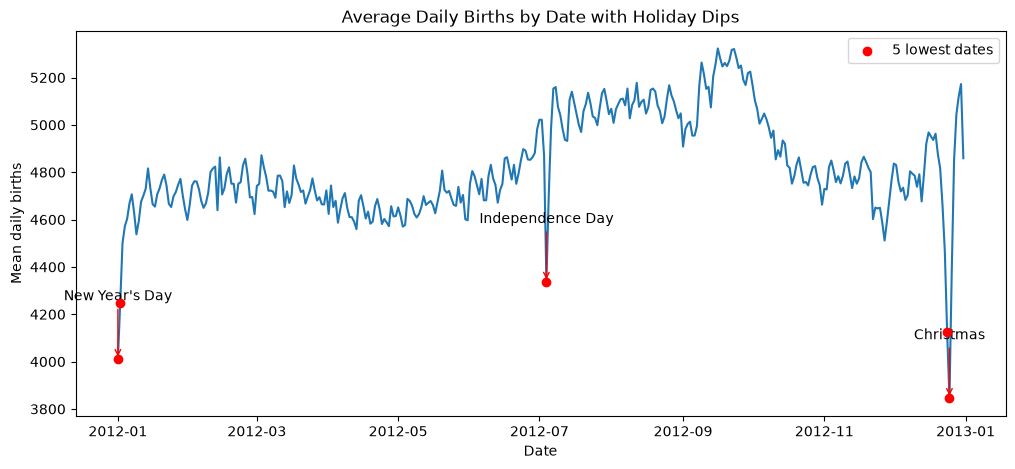

In [12]:
# Bonus: five dates with the lowest mean births
lowest5 = births_by_date['births'].nsmallest(5)
print(lowest5)

# Plot mean births by date
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(births_by_date.index, births_by_date['births'])

# Holiday dates (dummy year 2012)
holidays = {
    "New Year's Day": pd.Timestamp(2012, 1, 1),
    "Independence Day": pd.Timestamp(2012, 7, 4),
    "Christmas": pd.Timestamp(2012, 12, 25),
}

# Annotate each holiday dip with an arrow
for name, date in holidays.items():
    y = births_by_date.loc[date, 'births']
    ax.annotate(name, xy=(date, y), xytext=(date, y + 250),
                ha='center', arrowprops=dict(arrowstyle='->', color='red'))

# Mark the five lowest dates
ax.scatter(lowest5.index, lowest5.values, color='red', zorder=3, label='5 lowest dates')

# Labels and title
ax.set_xlabel('Date')
ax.set_ylabel('Mean daily births')
ax.set_title('Average Daily Births by Date with Holiday Dips')
ax.legend()
plt.show()

# Observation: births drop sharply on major holidays (Jan 1, Jul 4, Dec 25),
# which shows fewer scheduled or induced births on those days.